<a href="https://colab.research.google.com/github/mishbahulkhofid/KKA-Modul-3/blob/main/Laporan_%26_Dashboard_Analisis_Data_Penjualan_(e_commerce_sale).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Nama nama Anggota Kelompok**
1. Mishbahul Khofid 22
2. Ficka Putri Maulana 14
3. Diandra Kevin
4. Joshua Nataniel

In [11]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style('whitegrid')

# 1. Memuat dataset
df = pd.read_csv('shopping_trends.csv')

# 2. Eksplorasi awal & pemeriksaan data kosong/duplikat
print("=== INFO DATASET ===")
print(df.info())
print("\n=== CEK DATA KOSONG (MISSING VALUE) ===")
print(df.isnull().sum())
print("\nJumlah Data Duplikat:", df.duplicated().sum())
print("\n=== 5 BARIS PERTAMA ===")
print(df.head())
print("\n=== RINGKASAN STATISTIK ===")
print(df.describe())

# 3. Menghitung 5 Statistik Deskriptif Kunci
total_penjualan = df['Purchase Amount (USD)'].sum()
rata_transaksi = df['Purchase Amount (USD)'].mean()
median_transaksi = df['Purchase Amount (USD)'].median()
std_transaksi = df['Purchase Amount (USD)'].std()

total_kategori = df.groupby('Category')['Purchase Amount (USD)'].sum().sort_values(ascending=False)
kategori_terlaris = total_kategori.index[0]

total_wilayah = df.groupby('Location')['Purchase Amount (USD)'].sum().sort_values(ascending=False)
wilayah_teratas = total_wilayah.index[0]

rating_rata = df['Review Rating'].mean()

print("\n=== RINGKASAN STATISTIK KUNCI ===")
print(f"Total Penjualan       : ${total_penjualan:,.2f}")
print(f"Rata-rata Transaksi   : ${rata_transaksi:.2f} (Median: ${median_transaksi:.2f}, Std: ${std_transaksi:.2f})")
print(f"Kategori Terlaris     : {kategori_terlaris} (${total_kategori.iloc[0]:,.2f})")
print(f"Wilayah Teratas       : {wilayah_teratas} (${total_wilayah.iloc[0]:,.2f})")
print(f"Rating Rata-rata      : {rating_rata:.2f} / 5")

=== INFO DATASET ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3900 entries, 0 to 3899
Data columns (total 19 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Customer ID               3900 non-null   int64  
 1   Age                       3900 non-null   int64  
 2   Gender                    3900 non-null   object 
 3   Item Purchased            3900 non-null   object 
 4   Category                  3900 non-null   object 
 5   Purchase Amount (USD)     3900 non-null   int64  
 6   Location                  3900 non-null   object 
 7   Size                      3900 non-null   object 
 8   Color                     3900 non-null   object 
 9   Season                    3900 non-null   object 
 10  Review Rating             3900 non-null   float64
 11  Subscription Status       3900 non-null   object 
 12  Payment Method            3900 non-null   object 
 13  Shipping Type             3900 non-null   

### Ringkasan Statistik Kunci
* **Total Penjualan:** $233,081.00 (dari 3.900 transaksi bersih tanpa *missing value* maupun duplikat)
* **Rata-rata Transaksi:** $59.76 (Median: $60.00 | Standar Deviasi: $23.69)
* **Kategori Terlaris:** Clothing ($104,264.00)
* **Wilayah Teratas:** Montana ($5,784.00)
* **Rating Rata-rata:** 3.75 / 5.00

/tmp/ipykernel_757/30003925.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=total_kategori.values, y=total_kategori.index, palette='Blues_r')


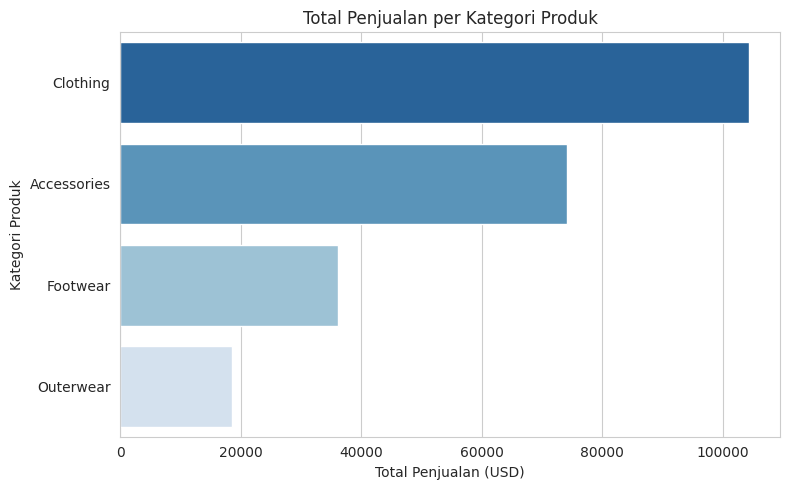

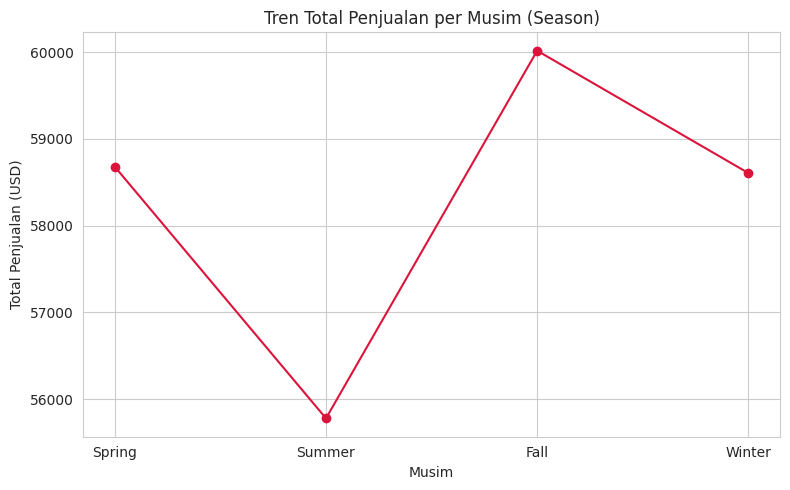

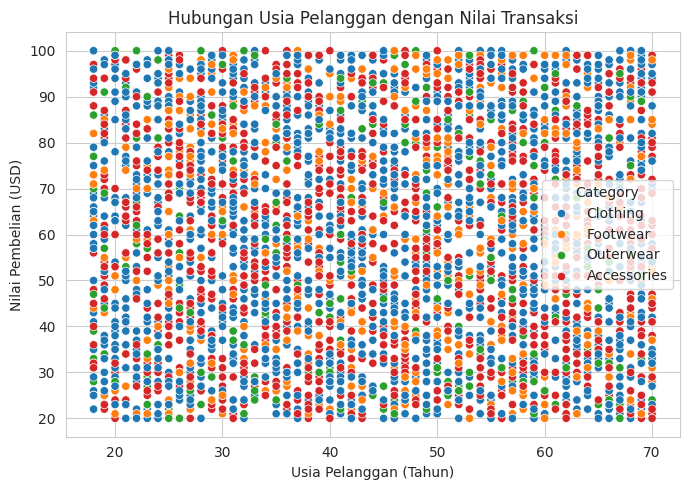

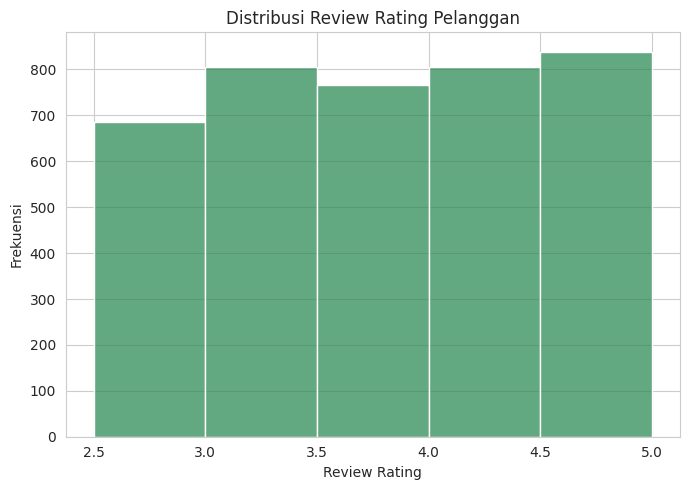

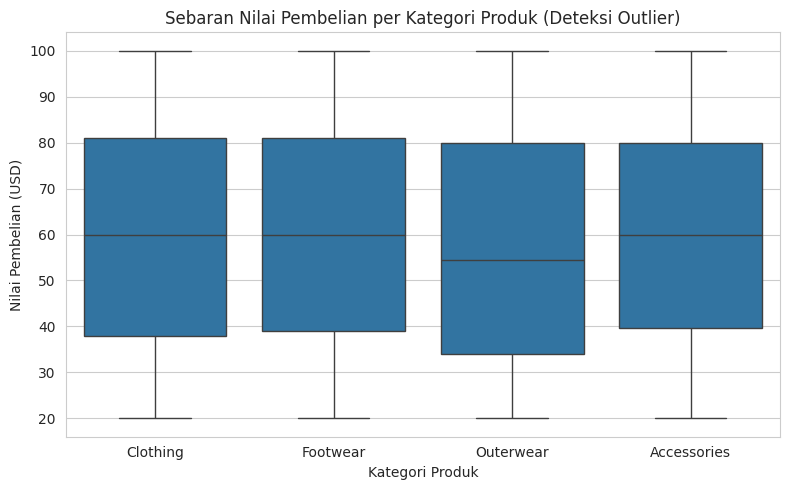

Q1: 39.0 | Q3: 81.0 | IQR: 42.0
Batas Bawah: -24.0 | Batas Atas: 144.0
Jumlah Outlier Terdeteksi: 0


In [12]:
# Grafik 1: Bar Chart - Total Penjualan per Kategori Produk (Latihan 2)
plt.figure(figsize=(8, 5))
sns.barplot(x=total_kategori.values, y=total_kategori.index, palette='Blues_r')
plt.title('Total Penjualan per Kategori Produk')
plt.xlabel('Total Penjualan (USD)')
plt.ylabel('Kategori Produk')
plt.tight_layout()
plt.show()

# Grafik 2: Line Chart - Tren Penjualan per Musim (Latihan 3)
urutan_musim = ['Spring', 'Summer', 'Fall', 'Winter']
tren_musiman = df.groupby('Season')['Purchase Amount (USD)'].sum().reindex(urutan_musim)
plt.figure(figsize=(8, 5))
plt.plot(tren_musiman.index, tren_musiman.values, marker='o', color='crimson')
plt.title('Tren Total Penjualan per Musim (Season)')
plt.xlabel('Musim')
plt.ylabel('Total Penjualan (USD)')
plt.tight_layout()
plt.show()

# Grafik 3: Scatter Plot - Hubungan Usia Pelanggan dengan Nilai Transaksi (Latihan 4)
plt.figure(figsize=(7, 5))
sns.scatterplot(data=df, x='Age', y='Purchase Amount (USD)', hue='Category')
plt.title('Hubungan Usia Pelanggan dengan Nilai Transaksi')
plt.xlabel('Usia Pelanggan (Tahun)')
plt.ylabel('Nilai Pembelian (USD)')
plt.tight_layout()
plt.show()

# Grafik 4: Histogram - Distribusi Review Rating Pelanggan (Latihan 5)
plt.figure(figsize=(7, 5))
sns.histplot(df['Review Rating'], bins=5, color='seagreen')
plt.title('Distribusi Review Rating Pelanggan')
plt.xlabel('Review Rating')
plt.ylabel('Frekuensi')
plt.tight_layout()
plt.show()

# Grafik 5: Boxplot - Sebaran Nilai Pembelian per Kategori & Deteksi Outlier (Latihan 5)
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x='Category', y='Purchase Amount (USD)')
plt.title('Sebaran Nilai Pembelian per Kategori Produk (Deteksi Outlier)')
plt.xlabel('Kategori Produk')
plt.ylabel('Nilai Pembelian (USD)')
plt.tight_layout()
plt.show()

# Perhitungan Matematis Aturan IQR pada Kolom Purchase Amount (USD)
Q1 = df['Purchase Amount (USD)'].quantile(0.25)
Q3 = df['Purchase Amount (USD)'].quantile(0.75)
IQR = Q3 - Q1
batas_bawah = Q1 - 1.5 * IQR
batas_atas = Q3 + 1.5 * IQR
outliers = df[(df['Purchase Amount (USD)'] < batas_bawah) | (df['Purchase Amount (USD)'] > batas_atas)]

print(f"Q1: {Q1} | Q3: {Q3} | IQR: {IQR}")
print(f"Batas Bawah: {batas_bawah} | Batas Atas: {batas_atas}")
print(f"Jumlah Outlier Terdeteksi: {len(outliers)}")

**Insight Bar Chart:**
Kategori **Clothing** mendominasi total pendapatan sebesar **$104.264** (44,7% dari total penjualan), diikuti oleh **Accessories** sebesar **$74.200**. Sebaliknya, kategori **Outerwear** mencatat kontribusi terendah sebesar **$18.524**, sehingga manajemen perlu mengevaluasi variasi produk dan strategi promosi pada kategori tersebut.



---



**Insight Line Chart:**
Performa penjualan bergerak fluktuatif antar-musim dengan titik terendah pada musim **Summer** (**$55.777**) dan melonjak ke puncak tertinggi pada musim **Fall** (**$60.018**). Kenaikan tajam di musim gugur menunjukkan tingginya kebutuhan pakaian transisi cuaca, sedangkan penurunan di musim panas menandakan perlunya kampanye promosi musiman (*summer sale*).


---

**Insight Scatter Plot:**
Sebaran titik antara usia pelanggan (18–70 tahun) dan nilai pembelian ($20–$100) membentuk pola acak merata di seluruh kelompok kategori tanpa tren naik maupun turun ($r = -0,01$). Hal ini membuktikan bahwa daya beli per transaksi tidak bergantung pada usia, sehingga strategi *bundling* produk dapat menargetkan seluruh segmen usia secara setara.


---

**Insight Histogram:**
Frekuensi penilaian pelanggan tersebar relatif merata pada rentang rating **2,5 hingga 5,0** dengan rata-rata **3,75 / 5,00**. Meskipun kelompok rating tertinggi (4,5–5,0) memiliki frekuensi terbanyak (837 transaksi), masih terdapat sekitar 684 transaksi dengan rating rendah (2,5–3,0) yang mengindikasikan perlunya peningkatan kualitas layanan maupun kesesuaian ukuran produk.


---

**Insight Boxplot & Deteksi Outlier (Aturan IQR):**
Seluruh kategori memiliki sebaran kotak (IQR) yang seragam dengan nilai tengah (median) di angka **$60** (kecuali *Outerwear* di **$55**) serta rentang minimum **$20** hingga maksimum **$100**. Berdasarkan perhitungan aturan IQR ($Q1 = \$39,00$, $Q3 = \$81,00$, $IQR = \$42,00$), batas bawah adalah $-\$24,00$ dan batas atas adalah $\$144,00$, sehingga ditemukan **0 outlier** karena kebijakan harga produk pada platform ini terkontrol ketat di rentang $\$20–\$100$ tanpa transaksi grosir abnormal.

/tmp/ipykernel_757/3547777301.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=total_kategori.values, y=total_kategori.index, palette='Blues_r', ax=axes[0, 0])


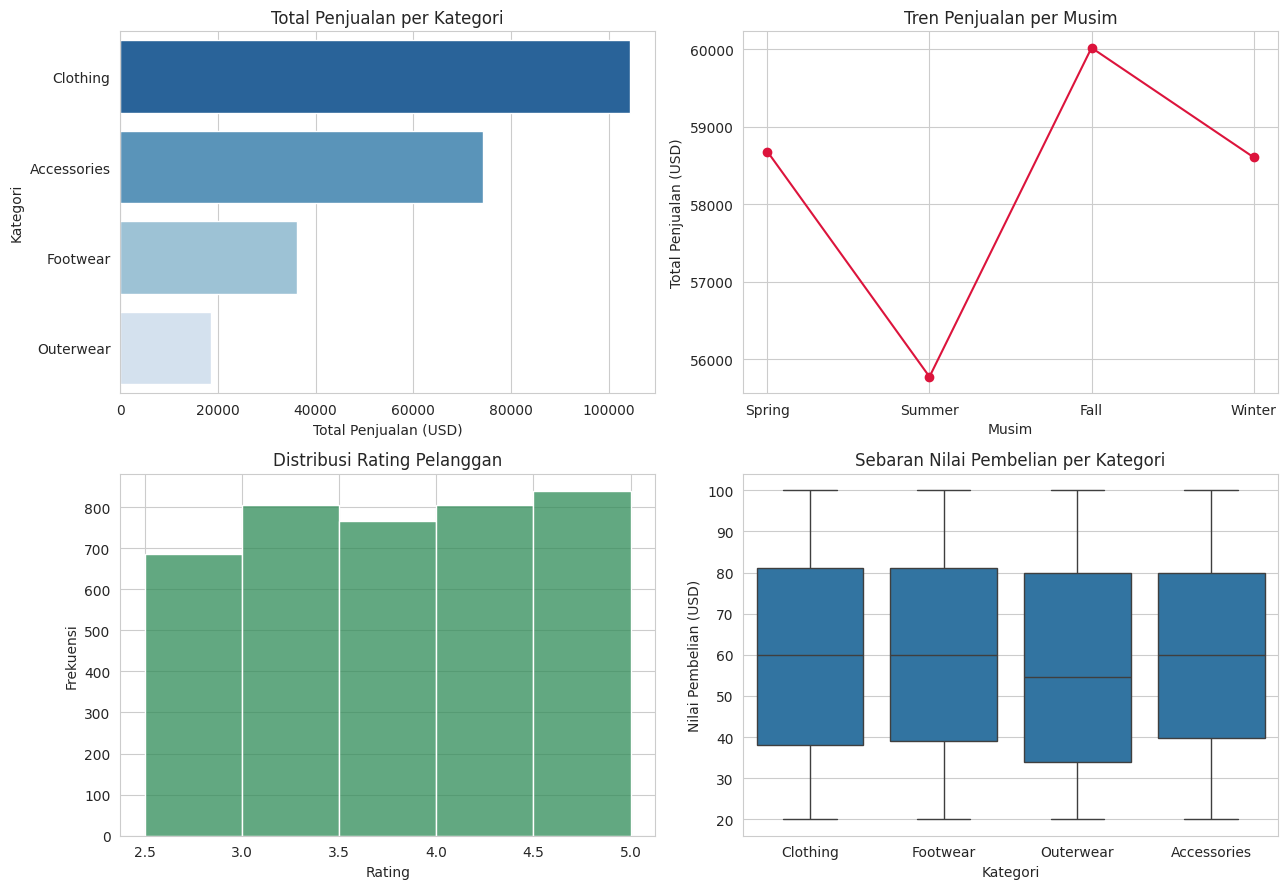

In [13]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9))

# Panel [0,0]: Bar Chart
sns.barplot(x=total_kategori.values, y=total_kategori.index, palette='Blues_r', ax=axes[0, 0])
axes[0, 0].set_title('Total Penjualan per Kategori')
axes[0, 0].set_xlabel('Total Penjualan (USD)')
axes[0, 0].set_ylabel('Kategori')

# Panel [0,1]: Line Chart
axes[0, 1].plot(tren_musiman.index, tren_musiman.values, marker='o', color='crimson')
axes[0, 1].set_title('Tren Penjualan per Musim')
axes[0, 1].set_xlabel('Musim')
axes[0, 1].set_ylabel('Total Penjualan (USD)')

# Panel [1,0]: Histogram
sns.histplot(df['Review Rating'], bins=5, color='seagreen', ax=axes[1, 0])
axes[1, 0].set_title('Distribusi Rating Pelanggan')
axes[1, 0].set_xlabel('Rating')
axes[1, 0].set_ylabel('Frekuensi')

# Panel [1,1]: Boxplot
sns.boxplot(data=df, x='Category', y='Purchase Amount (USD)', ax=axes[1, 1])
axes[1, 1].set_title('Sebaran Nilai Pembelian per Kategori')
axes[1, 1].set_xlabel('Kategori')
axes[1, 1].set_ylabel('Nilai Pembelian (USD)')

plt.tight_layout()
plt.show()

### Laporan Rekomendasi Bisnis
Berdasarkan hasil analisis 3.900 transaksi senilai **$233.081,00**, manajemen disarankan untuk memprioritaskan ketersediaan stok (*restock*) pada kategori **Clothing** dan **Accessories** menjelang puncak permintaan di musim **Fall** guna memaksimalkan pendapatan. Untuk mendongkrak penjualan pada musim **Summer** yang lesu serta kategori **Outerwear** yang kontribusinya paling rendah (**$18.524,00**), tim pemasaran perlu merancang program promosi *bundling* (misalnya paket pembelian *Clothing* disertai diskon *Outerwear* atau *Accessories*) serta menaikkan batas nilai transaksi rata-rata dari **$59,76** menjadi di atas **$75** melalui promo gratis ongkos kirim (*Free Shipping*) dengan minimum belanja tertentu.

Dari sisi geografis, wilayah dengan penjualan tertinggi seperti **Montana** (**$5.784,00**), **Illinois** (**$5.617,00**), dan **California** (**$5.605,00**) dapat dijadikan lokasi prioritas peluncuran kampanye loyalitas dan langganan (*Subscription*), sementara wilayah berpenjualan rendah perlu diberikan kode promo khusus pelanggan baru. Terakhir, karena rata-rata rating pelanggan masih berada di angka **3,75/5,00** dengan sebaran ulasan di bawah 3,0 yang cukup signifikan, perusahaan wajib melakukan audit kualitas pada item dengan ulasan rendah serta memperjelas panduan ukuran (*Size*) agar tingkat kepuasan pelanggan meningkat di periode promosi berikutnya.

=== LAPORAN ANALISIS DATA PENJUALAN (SHOPPING TRENDS) ===

1. Ringkasan Statistik
Total Penjualan      : $233,081.00 (dari 3.900 transaksi bersih, 0 missing value, 0 duplikat)
Rata-rata Transaksi  : $59.76 (Median: $60.00 | Standar Deviasi: $23.69)
Kategori Terlaris    : Clothing ($104,264.00)
Wilayah Teratas      : Montana ($5,784.00)
Rating Rata-rata     : 3.75 / 5.00

2. Temuan Utama (Insight)
- Clothing dan Accessories menjadi tulang punggung bisnis dengan kontribusi gabungan lebih dari 76% total pendapatan, sedangkan Outerwear tertinggal jauh di posisi terakhir ($18,524.00).
- Penjualan mencapai puncaknya pada musim Fall ($60,018.00) dan mengalami penurunan paling signifikan pada musim Summer ($55,777.00).
- Nilai belanja per transaksi ($20–$100) terdistribusi merata di seluruh rentang usia (18–70 tahun) dan memiliki selisih mean ($59.76) dan median ($60.00) yang sangat tipis, menandakan distribusi transaksi yang sangat simetris.

3. Potensi Outlier
- Berdasarkan perhitungan aturan IQR pada kolom Purchase Amount (USD), diperoleh Q1 = $39.00, Q3 = $81.00, dan IQR = $42.00, sehingga batas bawah adalah -$24.00 dan batas atas adalah $144.00.
- Hasil pengecekan boxplot maupun perhitungan IQR menunjukkan 0 outlier (tidak ada transaksi ekstrem). Hal ini terjadi karena kebijakan harga produk pada platform ritel ini berada dalam rentang standar yang terkontrol ketat antara $20.00 hingga $100.00 tanpa transaksi grosir abnormal.

4. Rekomendasi Bisnis
Berdasarkan hasil analisis 3.900 transaksi senilai $233.081,00, manajemen disarankan untuk memprioritaskan ketersediaan stok (restock) pada kategori Clothing dan Accessories menjelang puncak permintaan di musim Fall guna memaksimalkan pendapatan. Untuk mendongkrak penjualan pada musim Summer yang lesu serta kategori Outerwear yang kontribusinya paling rendah ($18.524,00), tim pemasaran perlu merancang program promosi bundling (misalnya paket pembelian Clothing disertai diskon Outerwear atau Accessories) serta menaikkan batas nilai transaksi rata-rata dari $59,76 menjadi di atas $75 melalui promo gratis ongkos kirim (Free Shipping) dengan minimum belanja tertentu. Dari sisi geografis, wilayah dengan penjualan tertinggi seperti Montana ($5.784,00), Illinois ($5.617,00), dan California ($5.605,00) dapat dijadikan lokasi prioritas peluncuran kampanye loyalitas dan langganan (Subscription), sementara wilayah berpenjualan rendah perlu diberikan kode promo khusus pelanggan baru. Terakhir, karena rata-rata rating pelanggan masih berada di angka 3,75/5,00 dengan sebaran ulasan di bawah 3,0 yang cukup signifikan, perusahaan wajib melakukan audit kualitas pada item dengan ulasan rendah serta memperjelas panduan ukuran (Size) agar tingkat kepuasan pelanggan meningkat di periode promosi berikutnya.